In [1]:
import numpy as np

import ufl
import dolfinx
import dolfinx.fem.petsc
from mpi4py import MPI
from petsc4py import PETSc

import matplotlib
import matplotlib.pyplot as plt

In [2]:
class LinearElasticity:
    def __init__(self, mesh_file, rank=0, gdim=3):
        """
        Initialize the LinearElasticity class with the mesh file.

        Parameters:
        mesh_file (str): Path to the mesh file.
        rank (int): Rank of the process (default is 0).
        gdim (int): Geometric dimension of the mesh (default is 3).
        """
        self.mesh_file = mesh_file
        self.rank = rank
        self.gdim = gdim
        self._read_mesh()
        self._setup_function_space()
        self._initialize_functions()

    def _read_mesh(self):
        """
        Read the mesh and facet tags from the specified mesh file.
        """
        try:
            self.mesh, self.tags, self.ft = dolfinx.io.gmshio.read_from_msh(self.mesh_file, MPI.COMM_WORLD, rank=self.rank, gdim=self.gdim)
            self.tdim = self.mesh.topology.dim
            self.fdim = self.tdim - 1
            self.mesh.topology.create_connectivity(self.fdim, self.tdim)
            self.boundary_facets = dolfinx.mesh.exterior_facet_indices(self.mesh.topology)

        except Exception as e:
            raise ValueError(f"Error reading mesh file {self.mesh_file}: {e}")

    def _setup_function_space(self):
        """
        Set up the function space for the problem.
        """
        
        self.V = dolfinx.fem.functionspace(self.mesh, ("Lagrange", 1, (self.mesh.geometry.dim,)))
        # self.V = dolfinx.fem.functionspace(self.mesh, ("Lagrange", 2, (self.mesh.geometry.dim,)))

        self.V_scalar = dolfinx.fem.functionspace(self.mesh, ("DG", 0))

        # In FEniCSx, "CG" is a shorthand for "Lagrange" for scalar fields, but it does not account for vector-valued fields by default. 
        # Hence, "Lagrange" provides more flexibility when specifying vector-valued elements or higher dimensions 
        # self.V = dolfinx.fem.functionspace(self.mesh, ("CG", 1))  # Continuous Galerkin space for displacement (does not work)

    def _initialize_functions(self):
        """
        Initialize trial and test functions.
        """
        self.u = ufl.TrialFunction(self.V)
        self.v = ufl.TestFunction(self.V)

    def parameters(self, rho, g, lmbda, mu):
        """
        Set material and physical parameters.

        Parameters:
        rho (float): Density.
        g (float): Gravitational acceleration.
        lmbda (float): First Lamé parameter.
        mu (float): Second Lamé parameter.
        """
        self.rho = rho
        self.g = g
        self.lmbda = lmbda
        self.mu = mu

    def compute_material_properties(material):
        G = material["E"] / (2 * (1 + material["nu"]))
        lame1 = material["nu"] * material["E"] / ((1 + material["nu"]) * (1 - 2 * material["nu"]))
        return G, lame1

    def validate_material(material):
        required_keys = ["E", "nu", "alpha", "rho", "geometry"]
        missing = [key for key in required_keys if key not in material]
        if missing:
            raise KeyError(f"Missing keys in material: {missing}")

    def boundary_conditions(self, radius_fi, radius_fo, height_fuel, radius_ci, radius_co, height_cladding, gap_pressure, coolant_pressure):
        """
        Define and set the boundary conditions.
        """

        # ----------------------        
        # Locate boundary facets
        # ----------------------

        # top_facets = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(x[2], height_fuel)
        # )

        # bottom_facets = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(x[2], 0.0)
        # )

        # outer_facets_fuel = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_fo)
        # )
        
        # inner_facets_cladding = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_ci)
        # )
        
        # outer_facets_cladding = dolfinx.mesh.locate_entities_boundary(
        #     self.mesh, self.fdim, lambda x: np.isclose(np.sqrt(x[0]**2 + x[1]**2), radius_co)
        # )

        # ---------------------
        # Mesh marker, meshtags
        # ---------------------

        # num_facets = self.mesh.topology.index_map(self.fdim).size_local
        # markers = np.zeros(num_facets, dtype=np.int32)

        # self.outer_fuel = 1
        # self.inner_cladding = 2
        # self.outer_cladding = 3
        # self.top = 4
        # self.bottom = 5

        # markers[outer_facets_fuel] = self.outer_fuel
        # markers[inner_facets_cladding] = self.inner_cladding
        # markers[outer_facets_cladding] = self.outer_cladding
        # markers[top_facets] = self.top
        # markers[bottom_facets] = self.bottom

        # self.facet_marker = dolfinx.mesh.meshtags(self.mesh, self.fdim, np.arange(num_facets, dtype=np.int32), markers)

        # ----------------------------------------------------------------
        # Locate dofs for Dirichlet boundary conditions from facet_markers
        # ----------------------------------------------------------------

        # self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.outer_fuel)
        # )

        # self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.inner_cladding)
        # )

        # self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.outer_cladding)
        # )

        # self.dofs_D_top = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.top)
        # )
        
        # self.dofs_D_bottom = dolfinx.fem.locate_dofs_topological(
        #     self.V, self.facet_marker.dim, self.facet_marker.find(self.bottom)
        # )

        # ----------------------------------------------------------
        # Locate dofs for Dirichlet boundary conditions from ft.find
        # ----------------------------------------------------------

        # self.dofs_D_bottom_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(1))

        # self.dofs_D_bottom_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, 
        # entities=self.ft.find(2))

        # self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(3))

        # self.dofs_D_top_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(4))

        # self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(5))

        # self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(6))

        # self.dofs_D_top_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(7))

        # ---------
        # Fuel dofs
        # ---------

        self.dofs_D_bottom_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(1))

        self.dofs_D_outer_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(3))

        self.dofs_D_top_fuel = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(4))

        # -------------
        # Cladding dofs
        # -------------

        self.dofs_D_bottom_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(2))

        self.dofs_D_inner_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(5))

        self.dofs_D_outer_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(6))

        self.dofs_D_top_cladding = dolfinx.fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(7))

        # -----------------------------
        # Dirichlet boundary conditions
        # -----------------------------

        # Clamped boundary conditions
        u_clamped = dolfinx.fem.Constant(
            self.mesh, (0.0, 0.0, 0.0)
        )

        self.bc_top_cladding  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_top_cladding,
            self.V
        )

        self.bc_top_fuel  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_top_fuel,
            self.V
        )
        

        self.bc_bottom_cladding  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_bottom_cladding,
            self.V
        )

        self.bc_bottom_fuel  = dolfinx.fem.dirichletbc(
            u_clamped,
            self.dofs_D_bottom_fuel,
            self.V
        )
        
        self.bc = [self.bc_bottom_fuel, self.bc_bottom_cladding, self.bc_top_fuel, self.bc_top_cladding]

        # ---------------------------
        # Neumann boundary conditions
        # ---------------------------

        self.normal = ufl.FacetNormal(self.mesh)

        self.gap_pressure = dolfinx.fem.Constant(
            self.mesh,
            dolfinx.default_scalar_type(gap_pressure)
        )

        self.coolant_pressure = dolfinx.fem.Constant(
            self.mesh,
            dolfinx.default_scalar_type(coolant_pressure)
        )
        
        self.traction_gap = self.gap_pressure * self.normal
        self.traction_coolant = self.coolant_pressure * self.normal

    def assemble_system(self):
        """
        Assemble the system for the linear elasticity problem.
        """

        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            # return ufl.sym(ufl.grad(u))
            return 0.5*(ufl.grad(u) + ufl.grad(u).T)

        # -----------
        # Body forces
        # -----------
        self.f = dolfinx.fem.Constant(
            self.mesh,
            (0.0, 0.0, - self.rho * self.g) # or ScalarType((0.0, 0.0, - self.rho * self.g))
        )

        # Mesure "ds"
        self.ds = ufl.Measure(
            "ds",
            domain=self.mesh,
            subdomain_data=self.ft
        )

        # ds_fo = self.ds(self.outer_fuel)        # or ds(10) with subdomain_data=self.ft
        # ds_ci = self.ds(self.inner_cladding)    # or ds(9) with subdomain_data=self.ft
        # ds_co = self.ds(self.outer_cladding)    # or ds(9) with subdomain_data=self.ft

        ds_fo = self.ds(3) # fuel outer
        ds_ci = self.ds(5) # cladding inner
        ds_co = self.ds(6) # cladding outer


        # material properties
        # lame1 = dolfinx.fem.Function(self.V_scalar)
        # cells_0 = dolfinx.mesh.locate_entities(self.mesh, self.tdim, 1)
        # cells_1 = dolfinx.mesh.locate_entities(self.mesh, self.tdim, 2)

        self.a = ufl.inner(sigma(self.u, self.lmbda, self.mu), epsilon(self.v)) * ufl.dx
        self.L_body_forces = ufl.inner(self.f, self.v) * ufl.dx
        self.L_tractions = ufl.inner(self.traction_coolant, self.v) * ds_co + ufl.inner(self.traction_gap, self.v) * ds_ci + ufl.inner(self.traction_gap, self.v) * ds_fo

        self.L = self.L_body_forces + self.L_tractions

        # Extraction of the linear and bi-linear form
        F = self.a - self.L # full variational form
        a, L = ufl.system(F)

        # We generate and compile the C code for these expressions using dolfinx.fem.form
        a_compiled = dolfinx.fem.form(a)
        L_compiled = dolfinx.fem.form(L)

        # Assemble the stiffness matrix
        A = dolfinx.fem.petsc.assemble_matrix(a_compiled)
        A.assemble()

        # Save the matrix to a text file
        viewer = PETSc.Viewer().createASCII("stiffness_matrix.txt")
        A.view(viewer)

        print(f"Matrix A is symmetric after assembly: {A.isSymmetric(1e-5)}")
        # If the matrix A isn't symmetric we need to exclude a whole class of iterative solvers (Conjugate Gradient).


    def solve(self):
        """
        Solve the linear elasticity problem.
        """

        # PETSc options
        # LU factorization, a direct solver method (similar to Gaussian elimination).
        # For non-symmetric problems, a Krylov solver for non-symmetric systems, such as GMRES is better.

        # petsc_options = {
        #     "ksp_type": "preonly",
        #     "pc_type": "lu",
        #     "pc_factor_mat_solver_type": "mumps",
        # }

        petsc_options = {
            "ksp_type": "gmres",
            "ksp_rtol": 1e-6,
            "ksp_atol": 1e-10,
            "ksp_max_it": 1000,
            "pc_type": "none",
        }

        jit_options = {
            "timeout": 20,
        }

        # Linear problem definition
        self.problem = dolfinx.fem.petsc.LinearProblem(
            self.a,
            self.L,
            bcs=self.bc,
            petsc_options=petsc_options,
            jit_options=jit_options,
        )

        # Solve the problem
        self.displacement = self.problem.solve()
        # self.displacement.x.scatter_forward() # scatter_forward is necessary for dolfinx ?

        # Compute stress and strain fields
        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            # return ufl.sym(ufl.grad(u))
            return 0.5*(ufl.grad(u) + ufl.grad(u).T)

        self.stress_field = sigma(self.displacement, self.lmbda, self.mu)
        self.strain_field = epsilon(self.displacement)

        # Solver options
        solver = self.problem.solver
        viewer = PETSc.Viewer().createASCII("log.solver")
        solver.view(viewer)
        # solver_output = open("lu_output.txt", "r")
        # for line in solver_output.readlines():
        #     print(line)

    def get_results(self):
        """
        Get the computed displacement, stress, and strain fields.

        Returns:
        displacement (Function): The displacement field.
        stress_field (ufl.Expr): The stress field.
        strain_field (ufl.Expr): The strain field.
        """
        return self.displacement, self.stress_field, self.strain_field
    
    def parse_matrix_file(self, filename):
        """
        Parse the matrix file and extract row, column, and value data.
        """
        rows = []
        cols = []
        values = []

        with open(filename, "r") as f:
            for line in f:
                if line.startswith("row"):
                    parts = line.split(":")
                    row_index = int(parts[0].split()[1])
                    entries = parts[1].strip().split("  ")
                    for entry in entries:
                        if entry:
                            col, value = entry.strip("()").split(", ")
                            rows.append(row_index)
                            cols.append(int(col))
                            values.append(float(value))

        return rows, cols, values

    def plot_sparsity_pattern(self, rows, cols):
        """
        Plot the sparsity pattern of the matrix.
        """
        import matplotlib.pyplot as plt

        plt.figure(figsize=(8, 8))
        plt.scatter(cols, rows, s=1, c='black')
        plt.gca().invert_yaxis()  # Invert y-axis for correct matrix indexing
        plt.xlabel("Columns")
        plt.ylabel("Rows")
        plt.title("Sparsity Pattern of Stiffness Matrix")
        plt.show()


------------------
Analytical volumes
------------------
Fuel volume, analytical = 6.283185307179586 m3
Cladding volume, analytical = 10.995574287564276 m3
Total volume, analytical = 17.27875959474386 m3
Info    : Reading '../../mesh/fuel_cladding_3d_slice.msh'...
Info    : 24 entities
Info    : 3123 nodes
Info    : 3892 elements
Info    : Done reading '../../mesh/fuel_cladding_3d_slice.msh'
-----------.
Mesh volumes
------------
Total volume, from mesh = 17.238449469118 m3
Fuel volume, from mesh = 6.242890304516142 m3
Cladding volume, from mesh = 10.995559164602044 m3
Matrix A is symmetric after assembly: True
displacement = f
stress_field = ({ A | A_{i_{46}, i_{47}} = 130769230769.23076 * ({ A | A_{i_{44}, i_{45}} = 0.5 * ((grad(f)) + ((grad(f))^T))[i_{44}, i_{45}] })[i_{46}, i_{47}] }) + ({ A | A_{i_{42}, i_{43}} = I[i_{42}, i_{43}] * 98076923076.92308 * (nabla_div(f)) })
strain_field = { A | A_{i_{48}, i_{49}} = 0.5 * ((grad(f)) + ((grad(f))^T))[i_{48}, i_{49}] }


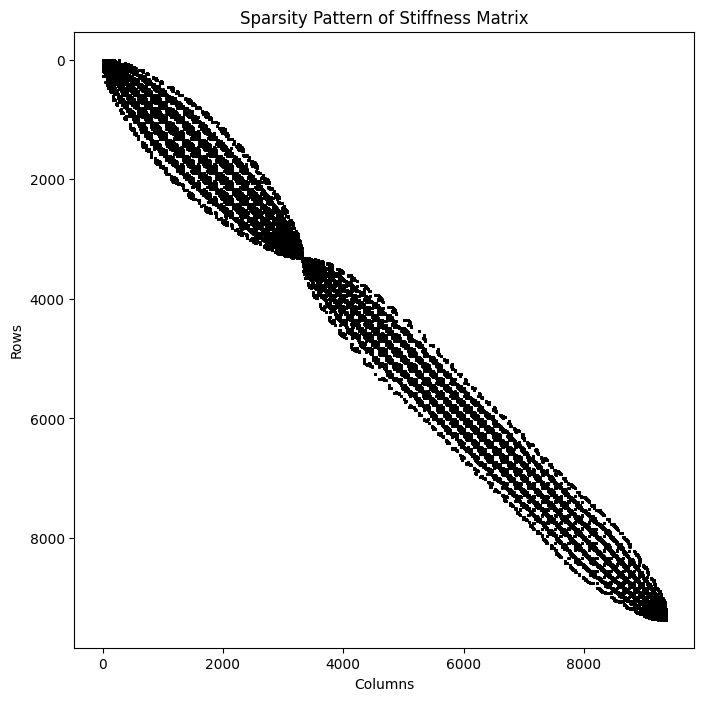

In [3]:
import numpy as np

from materials.fuel.uo2 import fuel
from materials.cladding.T91 import cladding
from materials.gap.gap import gap
from materials.coolant.lead import coolant

# Fuel properties
fuel_E = fuel["E"]
fuel_nu = fuel["nu"]
fuel_alpha = fuel["alpha"]
fuel_rho = fuel["rho"]
fuel_geometry = fuel["geometry"]

# Cladding properties
cladding_E = cladding["E"]
cladding_nu = cladding["nu"]
cladding_alpha = cladding["alpha"]
cladding_rho = cladding["rho"]
cladding_geometry = cladding["geometry"]

# Derived material parameters
fuel_G = fuel_E / (2 * (1 + fuel_nu))
fuel_lame1 = fuel_nu * fuel_E / ((1 + fuel_nu) * (1 - 2 * fuel_nu))
fuel_lame2 = fuel_G

cladding_G = cladding_E / (2 * (1 + cladding_nu))
cladding_lame1 = cladding_nu * cladding_E / ((1 + cladding_nu) * (1 - 2 * cladding_nu))
cladding_lame2 = cladding_G

# Analytical volume calculations
fuel_volume_analytical = np.pi * (fuel_geometry["radius_fo"]**2 - fuel_geometry["radius_fi"]**2) * fuel_geometry["height"]
cladding_volume_analytical = np.pi * (cladding_geometry["radius_co"]**2 - cladding_geometry["radius_ci"]**2) * cladding_geometry["height"]

print("------------------")
print("Analytical volumes")
print("------------------")
print(f"Fuel volume, analytical = {fuel_volume_analytical} m3")
print(f"Cladding volume, analytical = {cladding_volume_analytical} m3")
print(f"Total volume, analytical = {fuel_volume_analytical + cladding_volume_analytical} m3")

g = 0.0

# Problem declaration

problem = LinearElasticity(mesh_file='../../mesh/fuel_cladding_3d_slice.msh')

mt = problem.tags # MeshTags

# Integration measures for each subdomain
dx_subdomain = ufl.Measure("dx", domain=problem.mesh, subdomain_data=mt)
dx_fuel = dx_subdomain(1)      # Marker ID for fuel
dx_cladding = dx_subdomain(2)  # Marker ID for cladding

# Compute volumes
volume = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_subdomain))
volume_fuel = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_fuel))
volume_cladding = dolfinx.fem.assemble_scalar(dolfinx.fem.form(1 * dx_cladding))

# Print results
print("-----------.")
print("Mesh volumes")
print("------------")
print(f"Total volume, from mesh = {volume} m3")
print(f"Fuel volume, from mesh = {volume_fuel} m3")
print(f"Cladding volume, from mesh = {volume_cladding} m3")

problem.parameters(fuel_rho, g / volume, fuel_lame1, fuel_lame2)

problem.boundary_conditions(
    radius_fi=fuel_geometry["radius_fi"],
    radius_fo=fuel_geometry["radius_fo"],
    height_fuel=fuel_geometry["height"],
    radius_ci=cladding_geometry["radius_ci"],
    radius_co=cladding_geometry["radius_co"],
    height_cladding=cladding_geometry["height"],
    gap_pressure=gap["gap_pressure"],
    coolant_pressure=coolant["coolant_pressure"]
)
problem.assemble_system()
problem.solve()
displacement, stress_field, strain_field = problem.get_results()

print(f"displacement = {displacement}")
print(f"stress_field = {stress_field}")
print(f"strain_field = {strain_field}")

# Parse the matrix file containing the stiffness matrix
filename = "stiffness_matrix.txt"

# Parse the matrix file
rows, cols, values = problem.parse_matrix_file(filename)

# Plot the sparsity pattern
problem.plot_sparsity_pattern(rows, cols)

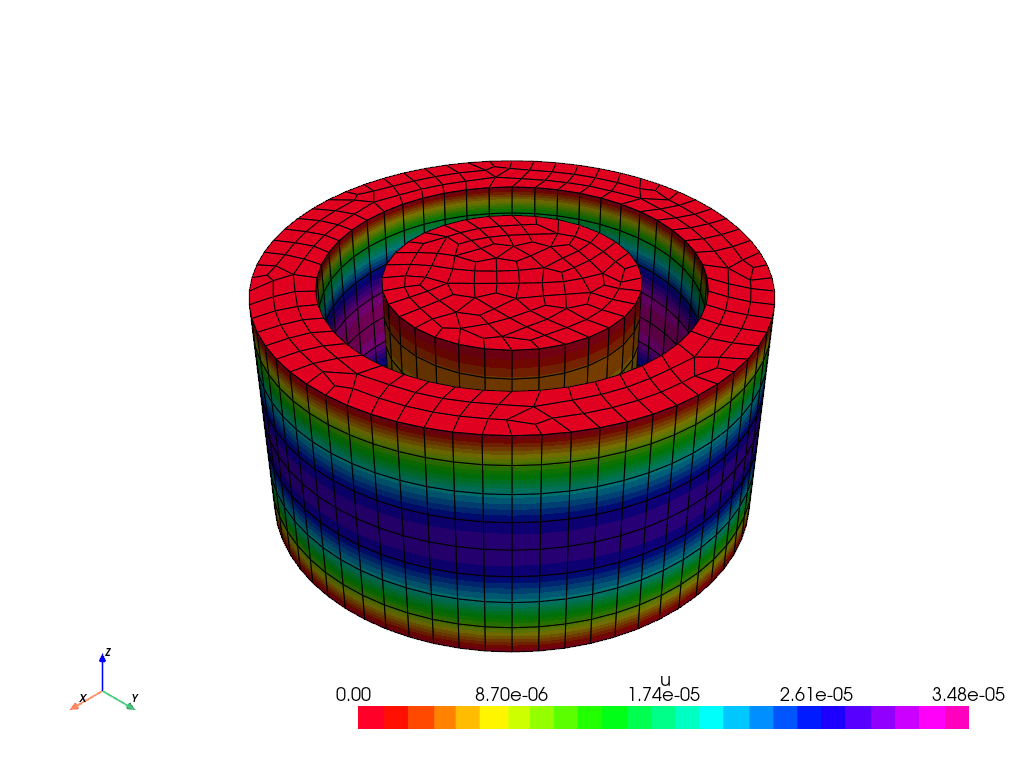

In [4]:
import pyvista
pyvista.start_xvfb(1.2) # 1.2 ?

# Create plotter and pyvista grid
p = pyvista.Plotter()
topology, cell_types, geometry = dolfinx.plot.vtk_mesh(problem.V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

# Attach vector values to grid and warp grid by vector
grid["u"] = displacement.x.array.reshape((geometry.shape[0], 3))
# grid["u"] = displacement.x.array.reshape(-1, 3)

p.add_mesh(grid, style="wireframe", color="k") # style = "points"
warped = grid.warp_by_vector("u")
# warped = grid.warp_by_vector("u", factor=1)
p.add_mesh(warped, show_edges=True, cmap=matplotlib.colormaps.get_cmap("gist_rainbow").resampled(25), lighting=True)
p.show_axes()

if not pyvista.OFF_SCREEN:
   p.show()
else:
   figure_as_array = p.screenshot("deflection.png")

# Paraview file
# with io.XDMFFile(problem.domain.comm, "deformation.xdmf", "w") as xdmf:
#     xdmf.write_mesh(problem.domain)
#     displacement.name = "Deformation"
#     xdmf.write_function(displacement)

In [5]:
# To extract and visualize the values of the displacement, stress, and strain fields in your problem, you can use FEniCSx's tools for interpolation and I/O to export the fields or query them at specific points. Here's how you can proceed:

# 1. Export Fields to a File
# Use XDMF or VTK formats to save the fields for visualization in external tools like ParaView.

with dolfinx.io.XDMFFile(problem.mesh.comm, "results.xdmf", "w") as xdmf:
    
    xdmf.write_mesh(problem.mesh)

    displacement.name = "displacement"
    xdmf.write_function(displacement)

mesh_nodes = len(problem.mesh.geometry.x)


In [6]:
V_stress = dolfinx.fem.functionspace(problem.mesh, ("Lagrange", 2, (problem.mesh.geometry.dim,)))
stress_expr = dolfinx.fem.Expression(stress_field, V_stress.element.interpolation_points())
stresses = dolfinx.fem.Function(V_stress)
# stresses.interpolate(stress_expr)

print(f"V_stress = {V_stress}")
print(f"stresses = {stresses}")
print(f"stress_expr = {stress_expr}")
print(f"stress_field = {stress_field}")


V_stress = FunctionSpace(<Mesh #0>, blocked element (Basix element (P, hexahedron, 2, gll_warped, unset, False, float64, []), (3,)))
stresses = f
stress_expr = <dolfinx.fem.function.Expression object at 0x7c1872fd68f0>
stress_field = ({ A | A_{i_{46}, i_{47}} = 130769230769.23076 * ({ A | A_{i_{44}, i_{45}} = 0.5 * ((grad(displacement)) + ((grad(displacement))^T))[i_{44}, i_{45}] })[i_{46}, i_{47}] }) + ({ A | A_{i_{42}, i_{43}} = I[i_{42}, i_{43}] * 98076923076.92308 * (nabla_div(displacement)) })


## Stress computation
As soon as the displacement is computed, we can compute various stress measures. We will compute the von Mises stress defined as $\sigma_m=\sqrt{\frac{3}{2}s:s}$ where $s$ is the deviatoric stress tensor $s(u)=\sigma(u)-\frac{1}{3}\mathrm{tr}(\sigma(u))I$.

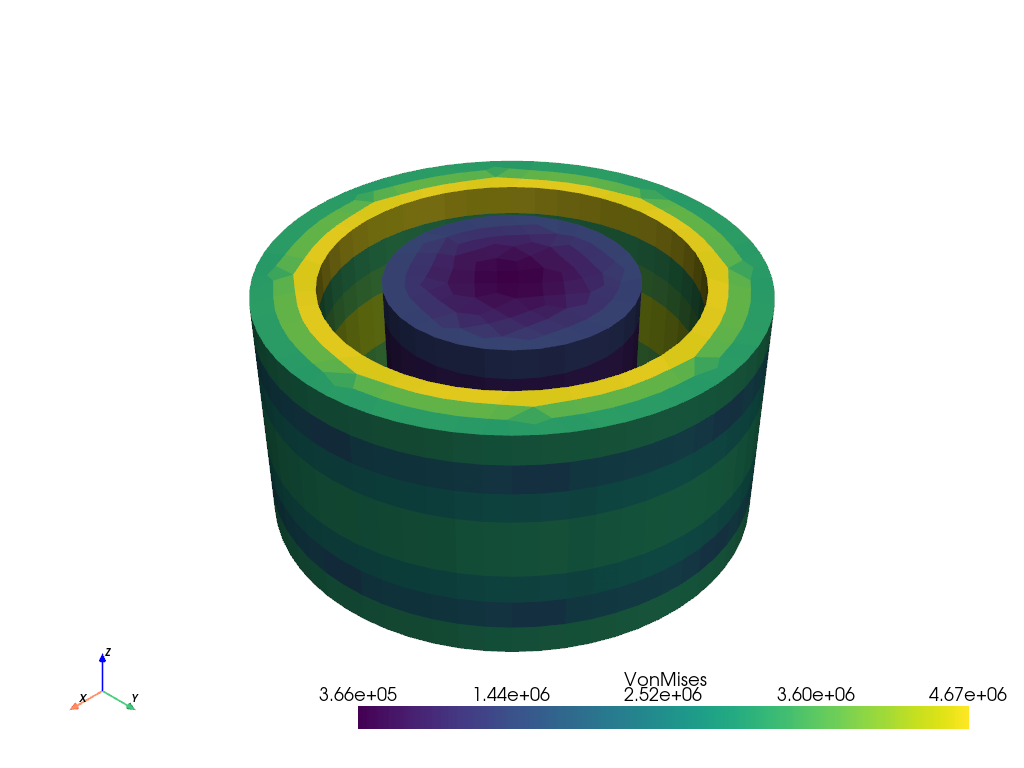

In [7]:
deviatoric_stress = stress_field - 1./3. * ufl.tr(stress_field) * ufl.Identity(len(displacement))
von_Mises = ufl.sqrt(3./2*ufl.inner(deviatoric_stress, deviatoric_stress))

V_von_mises = dolfinx.fem.functionspace(problem.mesh, ("DG", 0))
stress_expr = dolfinx.fem.Expression(von_Mises, V_von_mises.element.interpolation_points())
stresses = dolfinx.fem.Function(V_von_mises)
stresses.interpolate(stress_expr)

warped.cell_data["VonMises"] = stresses.x.petsc_vec
warped.set_active_scalars("VonMises")
p = pyvista.Plotter()
p.add_mesh(warped)
p.show_axes()
if not pyvista.OFF_SCREEN:
   p.show()
else:
   stress_figure = p.screenshot(f"stresses.png")

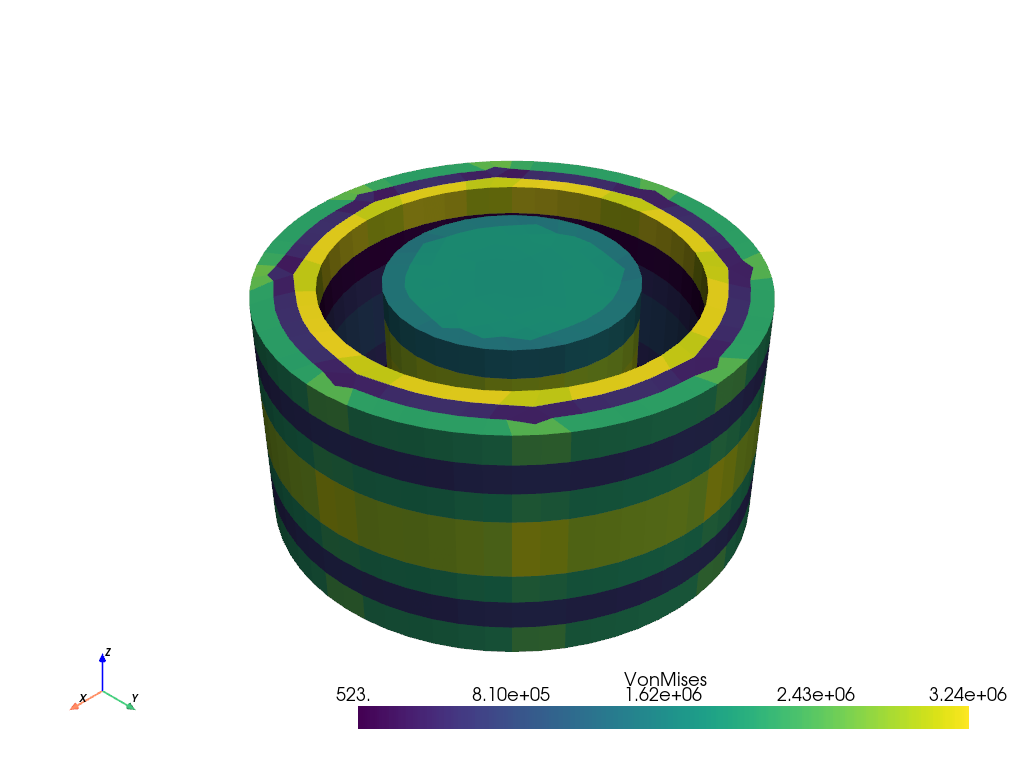

In [8]:
hydrostatic_stress = 1./3. * ufl.tr(stress_field) * ufl.Identity(len(displacement))

hydrostatic_stress_scalar = ufl.sqrt(ufl.inner(hydrostatic_stress, hydrostatic_stress))

V_von_mises = dolfinx.fem.functionspace(problem.mesh, ("DG", 0))
stress_expr = dolfinx.fem.Expression(hydrostatic_stress_scalar, V_von_mises.element.interpolation_points())
stresses = dolfinx.fem.Function(V_von_mises)
stresses.interpolate(stress_expr)

warped.cell_data["VonMises"] = stresses.x.petsc_vec
warped.set_active_scalars("VonMises")
p = pyvista.Plotter()
p.add_mesh(warped)
p.show_axes()
if not pyvista.OFF_SCREEN:
   p.show()
else:
   stress_figure = p.screenshot(f"stresses.png")

In [9]:
import logging, os

# Ensure the log directory exists (create it if it doesn't)
log_dir = './materials'
if not os.path.exists(log_dir):
    os.makedirs(log_dir)

# Set up logging to write to a file (overwrite the file if it already exists)
log_file = os.path.join(log_dir, 'log.material_properties')
logging.basicConfig(filename=log_file, level=logging.INFO, format='%(message)s', filemode='w')  # filemode='w' ensures overwriting
logger = logging.getLogger(__name__)

# Log material properties
logger.info("Fuel:")
logger.info(f"{fuel['name']}")
logger.info(f"Young's modulus = {fuel_E*1e-9:.2f} GPa")
logger.info(f"Poisson's ratio = {fuel_nu}")
logger.info(f"Shear modulus = {fuel_G*1e-9:.2f} GPa")
logger.info(f"Lamé first parameter = {fuel_lame1*1e-9:.2f} GPa")
logger.info(f"Lamé second parameter = {fuel_lame2*1e-9:.2f} GPa")
logger.info(f"Thermal expansion coefficient = {fuel_alpha} 1/K")
logger.info(f"Density = {fuel_rho} kg/m3")
logger.info(f"Geometry = {fuel_geometry}\n")

logger.info("Cladding:")
logger.info(f"{cladding['name']}")
logger.info(f"Young's modulus = {cladding_E*1e-9:.2f} GPa")
logger.info(f"Poisson's ratio = {cladding_nu}")
logger.info(f"Shear modulus = {cladding_G*1e-9:.2f} GPa")
logger.info(f"Lamé first parameter = {cladding_lame1*1e-9:.2f} GPa")
logger.info(f"Lamé second parameter = {cladding_lame2*1e-9:.2f} GPa")
logger.info(f"Thermal expansion coefficient = {cladding_alpha} 1/K")
logger.info(f"Density = {cladding_rho} kg/m3")
logger.info(f"Geometry = {cladding_geometry}\n")